# 04 · ERCOT Weather Impact Analysis

## Objectives

1. Validate the combined regional load–weather dataset.
2. Examine nonlinear relationships between temperature and electricity load.
3. Construct cooling-degree and heating-degree features.
4. Compare weather sensitivity across ERCOT's eight Weather Zones.
5. Investigate regional demand under extreme heat and cold.
6. Prepare weather and calendar features for later forecasting models.

**Scope:** This notebook reports descriptive associations and calendar-controlled, in-sample regressions. Its regression fit metrics do not establish out-of-sample forecasting accuracy. The displayed figures and tables are saved results from the original analysis and have not been reproduced in a new environment.


## Questions Addressed in This Notebook

- How does temperature affect ERCOT regional electricity load?
- Do extreme heat and cold both increase demand?
- Which weather zones show the strongest temperature sensitivity?
- How do high- and low-temperature conditions relate to load levels?
- Which weather features should be engineered for subsequent load forecasting?


### Environment Setup

The original notebook installed `seaborn` interactively using `%pip install seaborn`. That installation command and its machine-specific log have been removed from this public-facing version. Install dependencies from the repository's `requirements.txt` before running the notebook.


In [ ]:
# Import analysis libraries and configure notebook display settings.

from pathlib import Path

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

pd.set_option(
    "display.max_columns",
    100,
)

pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.3f}",
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
)


In [ ]:
# Locate the repository root, input Parquet file, and weather-analysis output directories.

current_directory = Path.cwd().resolve()

if (current_directory / "data").exists():
    project_root = current_directory
else:
    project_root = current_directory.parent

load_weather_data_path = (
    project_root
    / "data"
    / "modeling"
    / "regional_load_weather_2019_2025.parquet"
)

if not load_weather_data_path.exists():
    raise FileNotFoundError(
        "Required load–weather dataset not found: "
        f"{load_weather_data_path.relative_to(project_root)}"
    )

weather_tables_dir = (
    project_root
    / "report"
    / "tables"
    / "weather"
)

weather_figures_dir = (
    project_root
    / "report"
    / "figures"
    / "weather"
)

weather_tables_dir.mkdir(
    parents=True,
    exist_ok=True,
)

weather_figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", ".")

print("Load-weather data:", load_weather_data_path.relative_to(project_root))

print("Weather tables:", weather_tables_dir.relative_to(project_root))

print("Weather figures:", weather_figures_dir.relative_to(project_root))


Project root: .
Load-weather data: data/modeling/regional_load_weather_2019_2025.parquet
Weather tables: report/tables/weather
Weather figures: report/figures/weather


In [ ]:
# Load and validate the combined regional load–weather dataset.

weather_eda_data = pd.read_parquet(
    load_weather_data_path,
    engine="pyarrow",
)

required_analysis_columns = {
    "HourEnding_utc",
    "zone",
    "load_mw",
    "ERCOT",
    "source_year",
    "zone_total_mismatch_flag",
    "location_name",
    "temperature_2m",
    "apparent_temperature",
    "relative_humidity_2m",
    "dew_point_2m",
    "precipitation",
    "wind_speed_10m",
}

missing_analysis_columns = (
    required_analysis_columns
    - set(weather_eda_data.columns)
)

if missing_analysis_columns:
    raise ValueError(
        "Missing required analysis fields: "
        f"{sorted(missing_analysis_columns)}"
    )

weather_eda_data["HourEnding_utc"] = pd.to_datetime(
    weather_eda_data["HourEnding_utc"],
    utc=True,
    errors="raise",
)

print(
    "Weather EDA shape:",
    weather_eda_data.shape,
)

print(
    "UTC range:",
    weather_eda_data["HourEnding_utc"].min(),
    "to",
    weather_eda_data["HourEnding_utc"].max(),
)

print(
    "Zone count:",
    weather_eda_data["zone"].nunique(),
)

display(
    weather_eda_data[
        [
            "HourEnding_utc",
            "zone",
            "location_name",
            "load_mw",
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
        ]
    ].head(8)
)


Weather EDA shape: (490944, 18)
UTC range: 2019-01-01 07:00:00+00:00 to 2026-01-01 06:00:00+00:00
Zone count: 8


,HourEnding_utc,zone,location_name,load_mw,temperature_2m,relative_humidity_2m,wind_speed_10m
0,2019-01-01 07:00:00+00:00,COAST,Houston,"9,783.595",8.100,91,1.220
1,2019-01-01 07:00:00+00:00,EAST,Tyler,"1,264.194",4.600,96,2.620
2,2019-01-01 07:00:00+00:00,FWEST,Midland,"3,164.721",2.400,75,6.940
3,2019-01-01 07:00:00+00:00,NCENT,Dallas,"11,697.766",5.900,83,3.920
4,2019-01-01 07:00:00+00:00,NORTH,Wichita Falls,827.759,-0.500,70,7.100
5,2019-01-01 07:00:00+00:00,SCENT,San Antonio,"5,993.974",4.800,90,1.210
6,2019-01-01 07:00:00+00:00,SOUTH,McAllen,"3,066.891",9.400,69,1.250
7,2019-01-01 07:00:00+00:00,WEST,Abilene,"1,282.543",0.800,78,6.530


In [ ]:
# Check zone-hour counts, missing values, duplicate keys, and quality flags.

weather_value_columns = [
    "temperature_2m",
    "apparent_temperature",
    "relative_humidity_2m",
    "dew_point_2m",
    "precipitation",
    "wind_speed_10m",
]

weather_eda_startup_check = pd.Series({
    "row_count": len(weather_eda_data),
    "row_count_matches": (
        len(weather_eda_data) == 490_944
    ),
    "zone_count": weather_eda_data[
        "zone"
    ].nunique(),
    "duplicate_zone_time_keys": int(
        weather_eda_data.duplicated(
            subset=[
                "zone",
                "HourEnding_utc",
            ]
        ).sum()
    ),
    "missing_load_values": int(
        weather_eda_data[
            "load_mw"
        ].isna().sum()
    ),
    "missing_weather_values": int(
        weather_eda_data[
            weather_value_columns
        ].isna().sum().sum()
    ),
    "flagged_long_rows": int(
        weather_eda_data[
            "zone_total_mismatch_flag"
        ].sum()
    ),
    "utc_has_timezone": (
        weather_eda_data[
            "HourEnding_utc"
        ].dt.tz is not None
    ),
}, name="value")

print(
    weather_eda_startup_check.to_string()
)


row_count                   490944
row_count_matches             True
zone_count                       8
duplicate_zone_time_keys         0
missing_load_values              0
missing_weather_values           0
flagged_long_rows              384
utc_has_timezone              True


## Local-Time Calendar Features

Regional load and weather were joined on UTC timestamps. For calendar analysis, use ERCOT local time (`America/Chicago`), with daylight saving time handled by the timezone conversion. Because the source load timestamp denotes **Hour Ending**, subtract one hour before extracting local hour, weekday, and season.


In [ ]:
# Derive local interval-start timestamps and calendar features with DST-aware conversion.

weather_eda_data["interval_start_utc"] = (
    weather_eda_data["HourEnding_utc"]
    - pd.Timedelta(hours=1)
)

weather_eda_data["interval_start_local"] = (
    weather_eda_data["interval_start_utc"]
    .dt.tz_convert("America/Chicago")
)

weather_eda_data["local_year"] = (
    weather_eda_data[
        "interval_start_local"
    ].dt.year
)

weather_eda_data["month"] = (
    weather_eda_data[
        "interval_start_local"
    ].dt.month
)

weather_eda_data["day_of_week"] = (
    weather_eda_data[
        "interval_start_local"
    ].dt.dayofweek
)

weather_eda_data["hour"] = (
    weather_eda_data[
        "interval_start_local"
    ].dt.hour
)

weather_eda_data["is_weekend"] = (
    weather_eda_data[
        "day_of_week"
    ].isin(
        [
            5,
            6,
        ]
    )
)

weather_eda_data["season"] = np.select(
    condlist=[
        weather_eda_data["month"].isin(
            [12, 1, 2]
        ),
        weather_eda_data["month"].isin(
            [3, 4, 5]
        ),
        weather_eda_data["month"].isin(
            [6, 7, 8]
        ),
        weather_eda_data["month"].isin(
            [9, 10, 11]
        ),
    ],
    choicelist=[
        "Winter",
        "Spring",
        "Summer",
        "Fall",
    ],
    default="Unknown",
)

display(
    weather_eda_data[
        [
            "HourEnding_utc",
            "interval_start_utc",
            "interval_start_local",
            "local_year",
            "month",
            "day_of_week",
            "hour",
            "is_weekend",
            "season",
        ]
    ].head(8)
)


,HourEnding_utc,interval_start_utc,interval_start_local,local_year,month,day_of_week,hour,is_weekend,season
0,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
1,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
2,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
3,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
4,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
5,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
6,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter
7,2019-01-01 07:00:00+00:00,2019-01-01 06:00:00+00:00,2019-01-01 00:00:00-06:00,2019,1,1,0,False,Winter


## Temperature–Load Relationship

Electricity demand may have a nonlinear, U-shaped relationship with temperature: heating tends to raise load on cold days, while cooling tends to raise load on hot days. The following analysis is descriptive and does not isolate causal temperature effects.


In [ ]:
# Round temperatures into 1°C bins and summarize regional load within each bin.

weather_eda_data["temperature_bin_c"] = (
    weather_eda_data[
        "temperature_2m"
    ]
    .round()
    .astype(int)
)

zone_temperature_summary = (
    weather_eda_data
    .groupby(
        [
            "zone",
            "temperature_bin_c",
        ],
        as_index=False,
    )
    .agg(
        observation_count=(
            "load_mw",
            "count",
        ),
        average_load_mw=(
            "load_mw",
            "mean",
        ),
        median_load_mw=(
            "load_mw",
            "median",
        ),
        load_std_mw=(
            "load_mw",
            "std",
        ),
        actual_average_temperature_c=(
            "temperature_2m",
            "mean",
        ),
    )
    .sort_values(
        [
            "zone",
            "temperature_bin_c",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    zone_temperature_summary.head(20)
)


,zone,temperature_bin_c,observation_count,average_load_mw,median_load_mw,load_std_mw,actual_average_temperature_c
0,COAST,-12,1,"9,170.433","9,170.433",NaN,-12.100
1,COAST,-11,4,"9,203.382","9,153.627",172.731,-11.225
2,COAST,-10,2,"13,574.921","13,574.921","6,174.475",-9.950
3,COAST,-9,8,"10,970.244","8,912.010","3,821.682",-8.950
4,COAST,-8,18,"14,298.259","16,521.818","3,461.059",-7.994
5,COAST,-7,16,"13,149.792","10,869.216","3,851.952",-6.938
6,COAST,-6,15,"14,912.998","16,354.050","3,374.397",-6.073
7,COAST,-5,14,"15,744.830","16,630.914","2,687.876",-5.129
8,COAST,-4,22,"15,467.999","16,373.183","2,025.120",-3.936
9,COAST,-3,30,"15,959.933","17,000.809","2,463.482",-2.840


In [ ]:
# Filter sparse bins (fewer than 100 observations), normalize loads, and export the complete bin summary.

minimum_bin_observations = 100

stable_temperature_summary = zone_temperature_summary.loc[
    zone_temperature_summary[
        "observation_count"
    ] >= minimum_bin_observations
].copy()

zone_overall_average_load = (
    weather_eda_data
    .groupby(
        "zone"
    )
    ["load_mw"]
    .mean()
    .rename(
        "zone_overall_average_load_mw"
    )
)

stable_temperature_summary = (
    stable_temperature_summary.merge(
        zone_overall_average_load,
        on="zone",
        how="left",
        validate="many_to_one",
    )
)

stable_temperature_summary["load_index"] = (
    stable_temperature_summary[
        "average_load_mw"
    ]
    / stable_temperature_summary[
        "zone_overall_average_load_mw"
    ]
    * 100
)

temperature_summary_path = (
    weather_tables_dir
    / "zone_temperature_load_summary_2019_2025.csv"
)

zone_temperature_summary.to_csv(
    temperature_summary_path,
    index=False,
)

print(
    "Stable temperature summary shape:",
    stable_temperature_summary.shape,
)

print(
    "Temperature summary saved to:",
    temperature_summary_path.relative_to(project_root),
)


Stable temperature summary shape: (352, 9)
Temperature summary saved to: report/tables/weather/zone_temperature_load_summary_2019_2025.csv


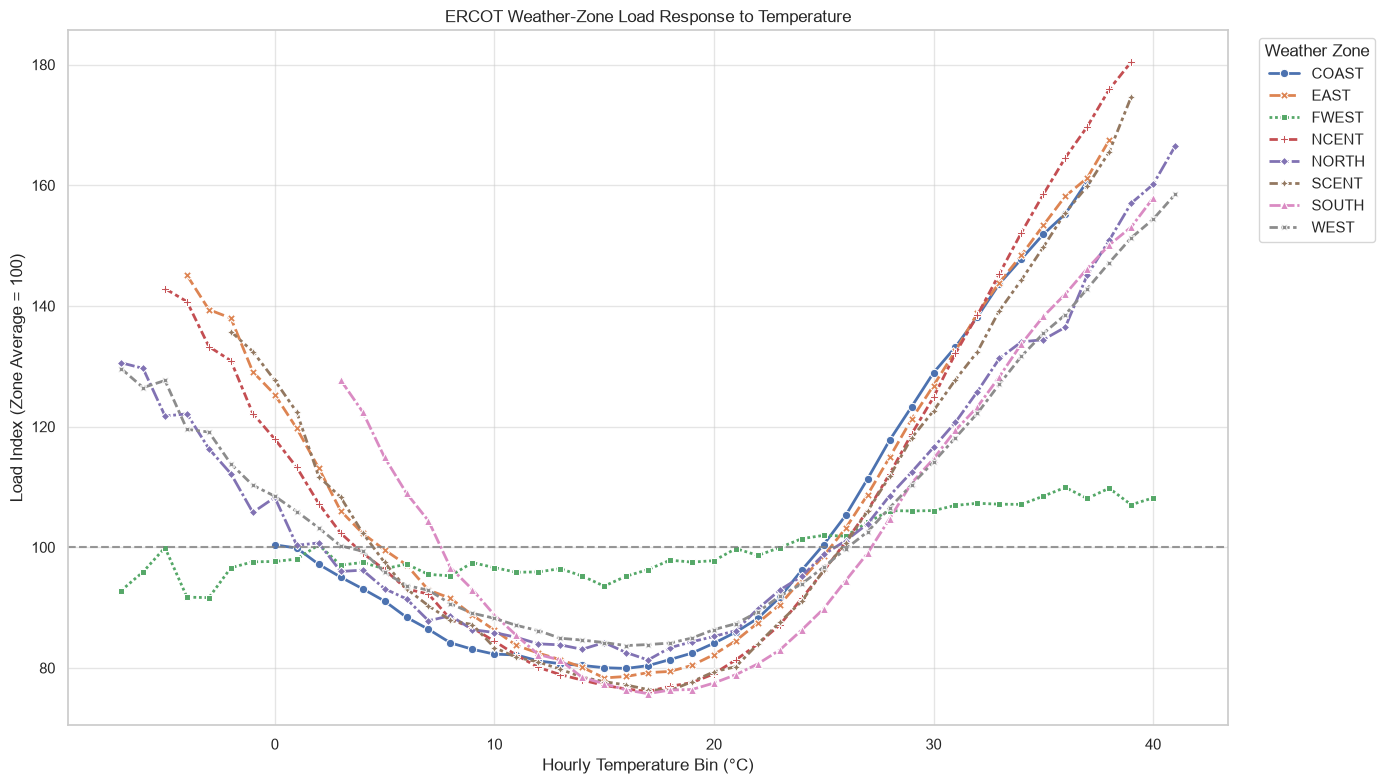

Temperature-load figure saved to: report/figures/weather/zone_temperature_load_response_2019_2025.png


In [ ]:
# Plot and save weather-zone temperature–load response curves.

temperature_figure, temperature_axis = plt.subplots(
    figsize=(14, 8)
)

sns.lineplot(
    data=stable_temperature_summary,
    x="temperature_bin_c",
    y="load_index",
    hue="zone",
    style="zone",
    markers=True,
    errorbar=None,
    linewidth=2,
    ax=temperature_axis,
)

temperature_axis.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
)

temperature_axis.set_title(
    "ERCOT Weather-Zone Load Response to Temperature"
)

temperature_axis.set_xlabel(
    "Hourly Temperature Bin (°C)"
)

temperature_axis.set_ylabel(
    "Load Index (Zone Average = 100)"
)

temperature_axis.legend(
    title="Weather Zone",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

temperature_figure.tight_layout()

temperature_figure_path = (
    weather_figures_dir
    / "zone_temperature_load_response_2019_2025.png"
)

temperature_figure.savefig(
    temperature_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Temperature-load figure saved to:",
    temperature_figure_path.relative_to(project_root),
)


### Temperature–Load Findings

- Seven of the eight ERCOT Weather Zones exhibit a pronounced nonlinear, U-shaped relationship between hourly temperature and regional load.
- Minimum load generally occurs between approximately 15°C and 18°C. Loads increase at both lower and higher temperatures, consistent with heating and cooling demand.
- High-temperature load response is particularly strong in NCENT, SCENT, EAST, and COAST. At extreme high temperatures, normalized load reaches approximately 160%–180% of the corresponding zone average.
- Low temperatures also increase load across most zones. Winter weather therefore remains important for reliability planning, even though ERCOT is primarily a summer-peaking system.
- FWEST is an important exception: its load index remains comparatively stable across most of the observed temperature range, indicating weaker temperature sensitivity than the other zones.
- These relationships are descriptive rather than causal. Calendar effects, longer-term load growth, and temperature vary together and are examined further in the subsequent regression section.


## Cooling- and Heating-Degree Features


Using an initial balance temperature of **18°C**, define hourly cooling and heating degree features as

\[
\mathrm{CDD}_t = \max(T_t - 18,\,0), \qquad
\mathrm{HDD}_t = \max(18 - T_t,\,0).
\]

CDD approximates temperature-driven cooling pressure; HDD approximates heating pressure. Both are *predictor features*, not forecasting models.


Cooling degree values are positive only above 18°C; heating degree values are positive only below 18°C. Additional comparison bands used below are **mild: 16–20°C**, **extreme heat: at least 35°C**, and **extreme cold: at most 0°C**.


In [ ]:
# Build cooling/heating degrees and extreme-temperature indicators; check feature consistency.

balance_temperature_c = 18.0

weather_eda_data["cooling_degree_c"] = np.maximum(
    weather_eda_data[
        "temperature_2m"
    ] - balance_temperature_c,
    0,
)

weather_eda_data["heating_degree_c"] = np.maximum(
    balance_temperature_c
    - weather_eda_data[
        "temperature_2m"
    ],
    0,
)

weather_eda_data["is_mild_temperature"] = (
    weather_eda_data[
        "temperature_2m"
    ].between(
        16,
        20,
        inclusive="both",
    )
)

weather_eda_data["is_extreme_heat"] = (
    weather_eda_data[
        "temperature_2m"
    ] >= 35
)

weather_eda_data["is_extreme_cold"] = (
    weather_eda_data[
        "temperature_2m"
    ] <= 0
)

both_degree_features_positive_mask = (
    (
        weather_eda_data[
            "cooling_degree_c"
        ] > 0
    )
    & (
        weather_eda_data[
            "heating_degree_c"
        ] > 0
    )
)

degree_feature_validation = pd.Series({
    "negative_cooling_degree_rows": int(
        (
            weather_eda_data[
                "cooling_degree_c"
            ] < 0
        ).sum()
    ),
    "negative_heating_degree_rows": int(
        (
            weather_eda_data[
                "heating_degree_c"
            ] < 0
        ).sum()
    ),
    "both_degree_features_positive": int(
        both_degree_features_positive_mask.sum()
    ),
    "mild_temperature_rows": int(
        weather_eda_data[
            "is_mild_temperature"
        ].sum()
    ),
    "extreme_heat_rows": int(
        weather_eda_data[
            "is_extreme_heat"
        ].sum()
    ),
    "extreme_cold_rows": int(
        weather_eda_data[
            "is_extreme_cold"
        ].sum()
    ),
}, name="value")

print(
    degree_feature_validation.to_string()
)


negative_cooling_degree_rows         0
negative_heating_degree_rows         0
both_degree_features_positive        0
mild_temperature_rows            61555
extreme_heat_rows                20596
extreme_cold_rows                10117


**Interpretation of sample counts:** The counts below represent **weather-zone hours**, not distinct ERCOT system hours. For the same UTC hour, COAST might reach 35°C and contribute one extreme-heat observation while EAST remains at 33°C and does not.


## Regional Load Under Extreme Weather

Compare each region's average load under extreme heat and cold against its own mean load under mild-temperature conditions (16–20°C). The mild-weather average is the zone-specific reference level. These differences are descriptive, not causal.


In [ ]:
# Assign extreme-cold, mild, extreme-heat, or other temperature regimes.

weather_eda_data["weather_regime"] = np.select(
    condlist=[
        weather_eda_data[
            "temperature_2m"
        ] <= 0,
        weather_eda_data[
            "temperature_2m"
        ].between(
            16,
            20,
            inclusive="both",
        ),
        weather_eda_data[
            "temperature_2m"
        ] >= 35,
    ],
    choicelist=[
        "Extreme Cold",
        "Mild",
        "Extreme Heat",
    ],
    default="Other",
)

extreme_weather_comparison_data = weather_eda_data.loc[
    weather_eda_data[
        "weather_regime"
    ].isin(
        [
            "Extreme Cold",
            "Mild",
            "Extreme Heat",
        ]
    )
].copy()

print(
    extreme_weather_comparison_data[
        "weather_regime"
    ].value_counts()
)


weather_regime
Mild            61555
Extreme Heat    20596
Extreme Cold    10117
Name: count, dtype: int64


In [ ]:
# Summarize regional load by temperature regime relative to each zone’s mild-weather reference.

zone_weather_regime_summary = (
    extreme_weather_comparison_data
    .groupby(
        [
            "zone",
            "weather_regime",
        ],
        as_index=False,
    )
    .agg(
        observation_count=(
            "load_mw",
            "count",
        ),
        average_load_mw=(
            "load_mw",
            "mean",
        ),
        median_load_mw=(
            "load_mw",
            "median",
        ),
        peak_load_mw=(
            "load_mw",
            "max",
        ),
        average_temperature_c=(
            "temperature_2m",
            "mean",
        ),
    )
)

mild_load_reference = (
    zone_weather_regime_summary
    .loc[
        zone_weather_regime_summary[
            "weather_regime"
        ] == "Mild",
        [
            "zone",
            "average_load_mw",
        ],
    ]
    .rename(
        columns={
            "average_load_mw": (
                "mild_average_load_mw"
            )
        }
    )
)

zone_weather_regime_summary = (
    zone_weather_regime_summary.merge(
        mild_load_reference,
        on="zone",
        how="left",
        validate="many_to_one",
    )
)

zone_weather_regime_summary[
    "load_index_vs_mild"
] = (
    zone_weather_regime_summary[
        "average_load_mw"
    ]
    / zone_weather_regime_summary[
        "mild_average_load_mw"
    ]
    * 100
)

zone_weather_regime_summary[
    "load_increase_vs_mild_pct"
] = (
    zone_weather_regime_summary[
        "load_index_vs_mild"
    ]
    - 100
)

zone_weather_regime_summary_path = (
    weather_tables_dir
    / "zone_extreme_weather_load_summary.csv"
)

zone_weather_regime_summary.to_csv(
    zone_weather_regime_summary_path,
    index=False,
)

display(
    zone_weather_regime_summary[
        [
            "zone",
            "weather_regime",
            "observation_count",
            "average_temperature_c",
            "average_load_mw",
            "load_index_vs_mild",
            "load_increase_vs_mild_pct",
        ]
    ].sort_values(
        [
            "zone",
            "weather_regime",
        ]
    )
)

print(
    "Extreme-weather summary saved to:",
    zone_weather_regime_summary_path.relative_to(project_root),
)


,zone,weather_regime,observation_count,average_temperature_c,average_load_mw,load_index_vs_mild,load_increase_vs_mild_pct
0,COAST,Extreme Cold,348,-2.786,"14,562.794",133.045,33.045
1,COAST,Extreme Heat,643,36.262,"21,058.602",192.390,92.390
2,COAST,Mild,7806,18.065,"10,945.770",100.000,0.000
3,EAST,Extreme Cold,1108,-3.049,"2,341.397",174.529,74.529
4,EAST,Extreme Heat,1499,36.622,"2,710.079",202.011,102.011
5,EAST,Mild,8491,18.068,"1,341.551",100.000,0.000
6,FWEST,Extreme Cold,2145,-3.366,"4,812.662",97.209,-2.791
7,FWEST,Extreme Heat,2815,37.079,"5,546.907",112.040,12.040
8,FWEST,Mild,7796,18.077,"4,950.830",100.000,0.000
9,NCENT,Extreme Cold,1308,-3.504,"19,220.627",174.910,74.910


Extreme-weather summary saved to: report/tables/weather/zone_extreme_weather_load_summary.csv


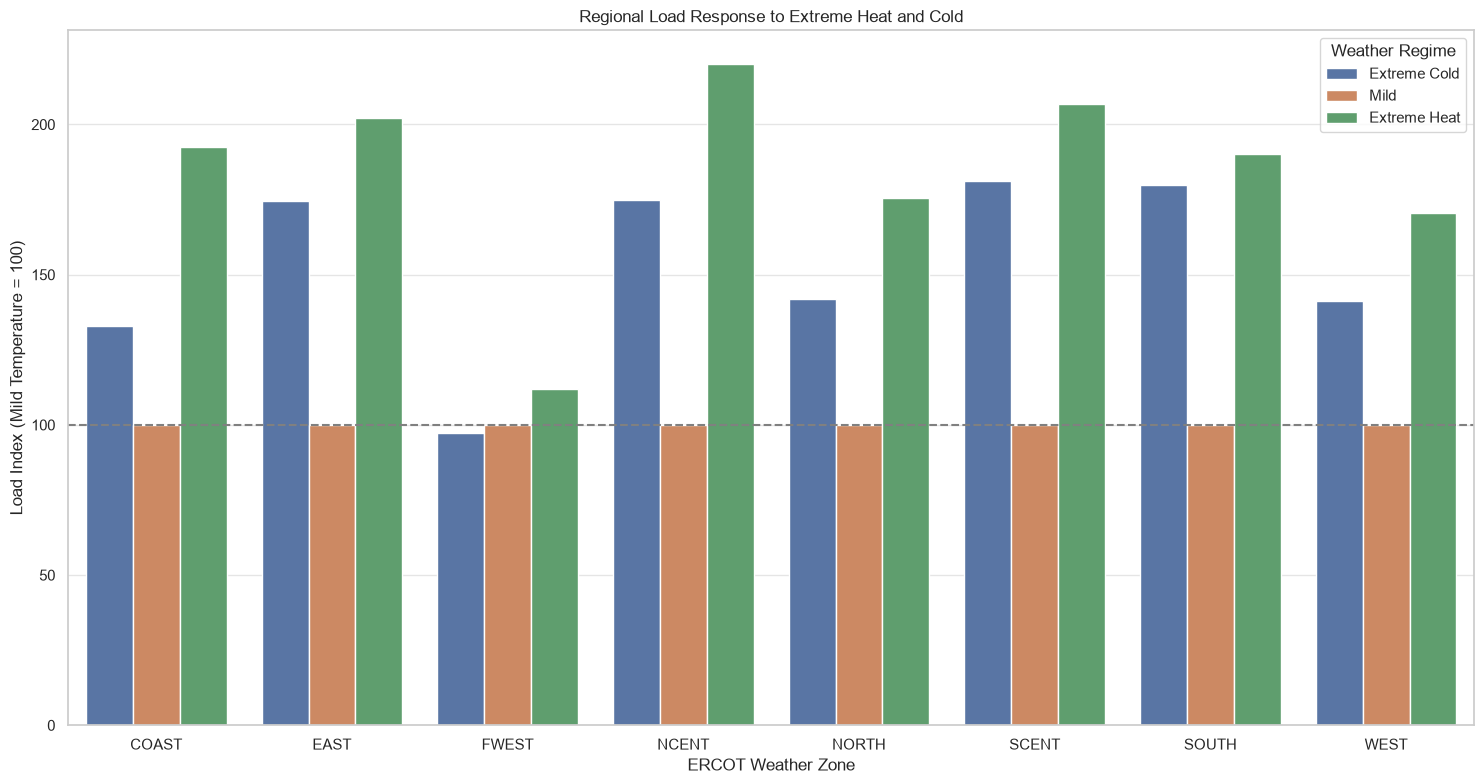

Extreme-weather figure saved to: report/figures/weather/regional_extreme_weather_load_response.png


In [ ]:
# Plot and save regional load indices under extreme cold, mild weather, and extreme heat.

weather_regime_order = [
    "Extreme Cold",
    "Mild",
    "Extreme Heat",
]

extreme_weather_figure, extreme_weather_axis = (
    plt.subplots(
        figsize=(15, 8)
    )
)

sns.barplot(
    data=zone_weather_regime_summary,
    x="zone",
    y="load_index_vs_mild",
    hue="weather_regime",
    hue_order=weather_regime_order,
    ax=extreme_weather_axis,
)

extreme_weather_axis.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1.5,
)

extreme_weather_axis.set_title(
    "Regional Load Response to Extreme Heat and Cold"
)

extreme_weather_axis.set_xlabel(
    "ERCOT Weather Zone"
)

extreme_weather_axis.set_ylabel(
    "Load Index (Mild Temperature = 100)"
)

extreme_weather_axis.legend(
    title="Weather Regime"
)

extreme_weather_figure.tight_layout()

extreme_weather_figure_path = (
    weather_figures_dir
    / "regional_extreme_weather_load_response.png"
)

extreme_weather_figure.savefig(
    extreme_weather_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Extreme-weather figure saved to:",
    extreme_weather_figure_path.relative_to(project_root),
)


**Forecasting interpretation:** FWEST may be influenced more strongly by lagged load, longer-term trends, or industrial activity than by temperature alone; this is a hypothesis to evaluate, not a conclusion from this notebook. Cooling and heating degree values are engineered weather predictors, rather than standalone models.


### Extreme-Weather Load Findings

- NCENT shows the largest extreme-heat increase: average load is approximately **120.3% above** its mild-temperature baseline.
- SCENT and EAST are sensitive to both extremes; extreme-heat mean load is approximately **106.7%** and **102.0%** above their respective mild-weather averages.
- COAST and SOUTH show strong heat-related increases, at approximately **92.4%** and **90.2%**, respectively.
- FWEST is considerably less temperature-sensitive. Extreme-heat load is approximately **12.0% above** its mild-weather baseline, while extreme-cold mean load is approximately **2.8% below** it.
- SOUTH has only **77 extreme-cold weather-zone-hour observations**. Its cold-weather comparison should be interpreted with caution.
- These estimates do not control for hour, day of week, year, or longer-term growth. The following regressions include calendar controls to investigate conditional associations.


## Calendar-Controlled Weather Sensitivity Regression

Fit a separate interpretable OLS regression for each ERCOT Weather Zone, with cooling and heating degree predictors and categorical calendar controls:

\[
\mathrm{Load}_{t,z} = \beta_{0,z}
  + \beta_{C,z}\,\mathrm{CDD}_{t,z}
  + \beta_{H,z}\,\mathrm{HDD}_{t,z}
  + \text{hour effects}
  + \text{weekday effects}
  + \text{month effects}
  + \text{year effects}
  + \varepsilon_{t,z}.
\]

The models use **HAC standard errors with a 168-hour maximum lag**. Coefficients describe conditional associations, not causal effects or validated out-of-sample forecasts.


### Regression Dependency

The original analysis installed `statsmodels` interactively. The `%pip install statsmodels` command and its environment-specific installation output have been removed here; install dependencies from the repository's `requirements.txt` instead.


In [ ]:
# Import statsmodels and report its version.

import statsmodels.formula.api as smf

import statsmodels

print(
    "Statsmodels version:",
    statsmodels.__version__,
)


Statsmodels version: 0.14.6


### Prepare Regression Samples

Exclude observations marked by the known zone-sum mismatch quality flag (48 system hours in 2021, equivalent to **384 zone-hour rows** across eight zones). Require complete target, degree, and calendar fields. Keep the original weather EDA dataset intact.

These regressions are explanatory analyses of historical data, **not** train/test-split predictive evaluations.


In [ ]:
# Exclude flagged rows and prepare categorical calendar predictors for regression.

regression_required_columns = [
    "load_mw",
    "cooling_degree_c",
    "heating_degree_c",
    "hour",
    "day_of_week",
    "month",
    "local_year",
    "zone",
]

regression_data = weather_eda_data.loc[
    ~weather_eda_data[
        "zone_total_mismatch_flag"
    ]
].copy()

regression_data = regression_data.dropna(
    subset=regression_required_columns
)

regression_data["hour"] = regression_data[
    "hour"
].astype("category")

regression_data["day_of_week"] = regression_data[
    "day_of_week"
].astype("category")

regression_data["month"] = regression_data[
    "month"
].astype("category")

regression_data["local_year"] = regression_data[
    "local_year"
].astype("category")

regression_data_check = pd.Series({
    "regression_row_count": len(
        regression_data
    ),
    "excluded_flagged_rows": (
        len(weather_eda_data)
        - len(regression_data)
    ),
    "zone_count": regression_data[
        "zone"
    ].nunique(),
    "missing_target_values": int(
        regression_data[
            "load_mw"
        ].isna().sum()
    ),
    "missing_cdd_values": int(
        regression_data[
            "cooling_degree_c"
        ].isna().sum()
    ),
    "missing_hdd_values": int(
        regression_data[
            "heating_degree_c"
        ].isna().sum()
    ),
}, name="value")

print(
    regression_data_check.to_string()
)


regression_row_count     490560
excluded_flagged_rows       384
zone_count                    8
missing_target_values         0
missing_cdd_values            0
missing_hdd_values            0


### Fit Separate Weather-Zone Regressions

Fit an OLS model per zone using calendar fixed effects and HAC covariance estimation (maximum lag: 168 hours). Summarize each region's cooling and heating coefficients in MW per degree and as a percentage of the zone's mean load during mild weather.


In [ ]:
# Fit per-zone OLS models with calendar controls and HAC standard errors; collect coefficients.

weather_sensitivity_formula = (
    "load_mw ~ "
    "cooling_degree_c + "
    "heating_degree_c + "
    "C(hour) + "
    "C(day_of_week) + "
    "C(month) + "
    "C(local_year)"
)

weather_sensitivity_models = {}

weather_sensitivity_records = []

for current_zone in sorted(
    regression_data[
        "zone"
    ].unique()
):
    current_zone_data = regression_data.loc[
        regression_data[
            "zone"
        ] == current_zone
    ].copy()

    current_model = smf.ols(
        formula=weather_sensitivity_formula,
        data=current_zone_data,
    )

    current_result = current_model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": 168
        },
    )

    weather_sensitivity_models[
        current_zone
    ] = current_result

    current_mild_average_load = float(
        mild_load_reference.loc[
            mild_load_reference[
                "zone"
            ] == current_zone,
            "mild_average_load_mw",
        ].iloc[0]
    )

    cooling_coefficient_mw = float(
        current_result.params[
            "cooling_degree_c"
        ]
    )

    heating_coefficient_mw = float(
        current_result.params[
            "heating_degree_c"
        ]
    )

    weather_sensitivity_records.append({
        "zone": current_zone,
        "observation_count": int(
            current_result.nobs
        ),
        "cooling_mw_per_degree_c": (
            cooling_coefficient_mw
        ),
        "cooling_standard_error": float(
            current_result.bse[
                "cooling_degree_c"
            ]
        ),
        "cooling_p_value": float(
            current_result.pvalues[
                "cooling_degree_c"
            ]
        ),
        "heating_mw_per_degree_c": (
            heating_coefficient_mw
        ),
        "heating_standard_error": float(
            current_result.bse[
                "heating_degree_c"
            ]
        ),
        "heating_p_value": float(
            current_result.pvalues[
                "heating_degree_c"
            ]
        ),
        "mild_average_load_mw": (
            current_mild_average_load
        ),
        "cooling_pct_of_mild_per_degree": (
            cooling_coefficient_mw
            / current_mild_average_load
            * 100
        ),
        "heating_pct_of_mild_per_degree": (
            heating_coefficient_mw
            / current_mild_average_load
            * 100
        ),
        "r_squared": float(
            current_result.rsquared
        ),
        "adjusted_r_squared": float(
            current_result.rsquared_adj
        ),
    })

    print(
        f"Completed regression for {current_zone}"
    )

weather_sensitivity_summary = pd.DataFrame(
    weather_sensitivity_records
)

weather_sensitivity_summary = (
    weather_sensitivity_summary.sort_values(
        "cooling_pct_of_mild_per_degree",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

display(
    weather_sensitivity_summary[
        [
            "zone",
            "observation_count",
            "cooling_mw_per_degree_c",
            "cooling_pct_of_mild_per_degree",
            "heating_mw_per_degree_c",
            "heating_pct_of_mild_per_degree",
            "r_squared",
            "adjusted_r_squared",
        ]
    ]
)


Completed regression for COAST
Completed regression for EAST
Completed regression for FWEST
Completed regression for NCENT
Completed regression for NORTH
Completed regression for SCENT
Completed regression for SOUTH
Completed regression for WEST


,zone,observation_count,cooling_mw_per_degree_c,cooling_pct_of_mild_per_degree,heating_mw_per_degree_c,heating_pct_of_mild_per_degree,r_squared,adjusted_r_squared
0,NCENT,61320,569.820,5.185,369.903,3.366,0.911,0.911
1,EAST,61320,62.785,4.680,43.991,3.279,0.879,0.879
2,SCENT,61320,278.679,4.619,204.704,3.393,0.904,0.904
3,COAST,61320,458.145,4.186,190.146,1.737,0.901,0.901
4,SOUTH,61320,117.375,3.931,136.506,4.572,0.904,0.904
5,NORTH,61320,30.028,3.160,19.433,2.045,0.926,0.926
6,WEST,61320,32.388,2.966,22.428,2.054,0.844,0.844
7,FWEST,61320,29.789,0.602,8.765,0.177,0.975,0.975


### Export Regression Summary


In [ ]:
# Write the weather-sensitivity regression summary to CSV.

weather_sensitivity_summary_path = (
    weather_tables_dir
    / "zone_calendar_controlled_weather_sensitivity.csv"
)

weather_sensitivity_summary.to_csv(
    weather_sensitivity_summary_path,
    index=False,
)

print(
    weather_sensitivity_summary[
        [
            "zone",
            "cooling_mw_per_degree_c",
            "cooling_pct_of_mild_per_degree",
            "heating_mw_per_degree_c",
            "heating_pct_of_mild_per_degree",
            "r_squared",
        ]
    ].round(3).to_string(
        index=False
    )
)

print(
    "\nRegression summary saved to:",
    weather_sensitivity_summary_path.relative_to(project_root),
)


 zone  cooling_mw_per_degree_c  cooling_pct_of_mild_per_degree  heating_mw_per_degree_c  heating_pct_of_mild_per_degree  r_squared
NCENT                  569.820                           5.185                  369.903                           3.366      0.911
 EAST                   62.785                           4.680                   43.991                           3.279      0.879
SCENT                  278.679                           4.619                  204.704                           3.393      0.904
COAST                  458.145                           4.186                  190.146                           1.737      0.901
SOUTH                  117.375                           3.931                  136.506                           4.572      0.904
NORTH                   30.028                           3.160                   19.433                           2.045      0.926
 WEST                   32.388                           2.966                   22

### Calendar-Controlled Weather Sensitivity Findings

- With hour, weekday, month, and year controls, both cooling-degree and heating-degree coefficients are positive in all eight Weather Zones, indicating positive conditional associations with regional load.
- NCENT has the largest absolute estimated weather response: each additional cooling degree above 18°C is associated with approximately **569.8 MW** of additional load, and each heating degree with approximately **369.9 MW**.
- COAST also has strong cooling sensitivity, at approximately **458.1 MW per cooling degree**, but substantially weaker heating sensitivity.
- FWEST remains the least temperature-sensitive zone by these measures: cooling and heating coefficients correspond to approximately **0.60%** and **0.18%** of its mild-weather average load per degree, respectively.
- High **in-sample R²** does not establish out-of-sample forecasting performance. Chronological validation and comparisons with lag-24 and lag-168 baselines are needed before evaluating predictive performance.


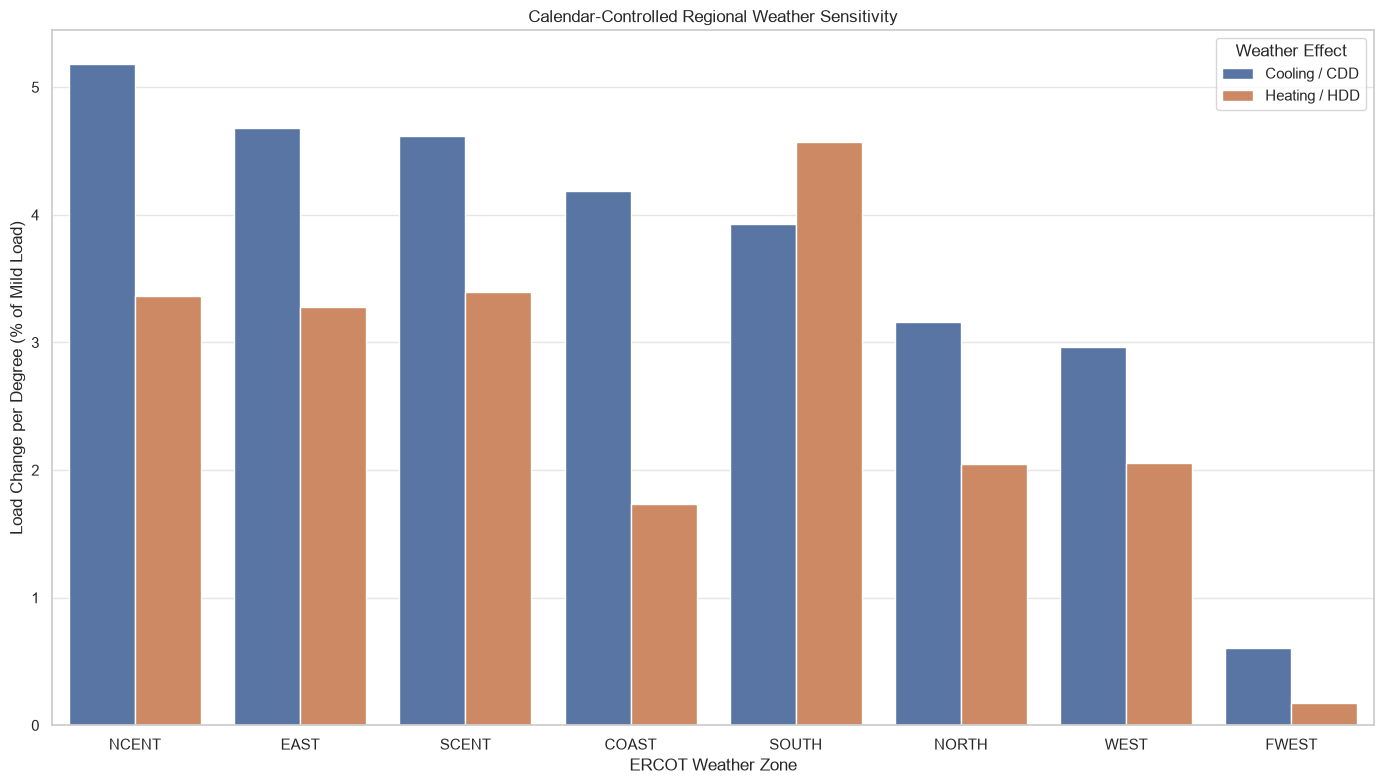

Weather-sensitivity figure saved to: report/figures/weather/calendar_controlled_weather_sensitivity.png


In [ ]:
# Plot cooling/heating regression coefficients normalized to mild-weather load.

weather_coefficient_plot_data = (
    weather_sensitivity_summary[
        [
            "zone",
            "cooling_pct_of_mild_per_degree",
            "heating_pct_of_mild_per_degree",
        ]
    ]
    .melt(
        id_vars=["zone"],
        value_vars=[
            "cooling_pct_of_mild_per_degree",
            "heating_pct_of_mild_per_degree",
        ],
        var_name="sensitivity_type",
        value_name="load_change_pct_per_degree",
    )
)

weather_coefficient_plot_data[
    "sensitivity_type"
] = weather_coefficient_plot_data[
    "sensitivity_type"
].map({
    "cooling_pct_of_mild_per_degree": (
        "Cooling / CDD"
    ),
    "heating_pct_of_mild_per_degree": (
        "Heating / HDD"
    ),
})

coefficient_figure, coefficient_axis = plt.subplots(
    figsize=(14, 8)
)

sns.barplot(
    data=weather_coefficient_plot_data,
    x="zone",
    y="load_change_pct_per_degree",
    hue="sensitivity_type",
    ax=coefficient_axis,
)

coefficient_axis.set_title(
    "Calendar-Controlled Regional Weather Sensitivity"
)

coefficient_axis.set_xlabel(
    "ERCOT Weather Zone"
)

coefficient_axis.set_ylabel(
    "Load Change per Degree (% of Mild Load)"
)

coefficient_axis.legend(
    title="Weather Effect"
)

coefficient_figure.tight_layout()

coefficient_figure_path = (
    weather_figures_dir
    / "calendar_controlled_weather_sensitivity.png"
)

coefficient_figure.savefig(
    coefficient_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Weather-sensitivity figure saved to:",
    coefficient_figure_path.relative_to(project_root),
)


In [ ]:
# Export the weather and calendar feature table for subsequent forecasting work.

weather_model_feature_columns = [
    "HourEnding_utc",
    "interval_start_utc",
    "interval_start_local",
    "zone",
    "location_name",
    "load_mw",
    "ERCOT",
    "source_year",
    "zone_total_mismatch_flag",
    "temperature_2m",
    "apparent_temperature",
    "relative_humidity_2m",
    "dew_point_2m",
    "precipitation",
    "wind_speed_10m",
    "local_year",
    "month",
    "day_of_week",
    "hour",
    "is_weekend",
    "season",
    "cooling_degree_c",
    "heating_degree_c",
    "is_mild_temperature",
    "is_extreme_heat",
    "is_extreme_cold",
]

weather_model_features = weather_eda_data[
    weather_model_feature_columns
].copy()

modeling_data_dir = (
    project_root
    / "data"
    / "modeling"
)

modeling_data_dir.mkdir(
    parents=True,
    exist_ok=True,
)

weather_model_features_path = (
    modeling_data_dir
    / "regional_load_weather_features_2019_2025.parquet"
)

weather_model_features.to_parquet(
    weather_model_features_path,
    index=False,
    engine="pyarrow",
)

weather_feature_file_check = pd.Series({
    "row_count": len(
        weather_model_features
    ),
    "column_count": len(
        weather_model_features.columns
    ),
    "zone_count": weather_model_features[
        "zone"
    ].nunique(),
    "duplicate_zone_time_keys": int(
        weather_model_features.duplicated(
            subset=[
                "zone",
                "HourEnding_utc",
            ]
        ).sum()
    ),
    "missing_core_feature_values": int(
        weather_model_features[
            [
                "load_mw",
                "cooling_degree_c",
                "heating_degree_c",
            ]
        ].isna().sum().sum()
    ),
}, name="value")

print(
    weather_feature_file_check.to_string()
)

print(
    "\nWeather model features saved to:",
    weather_model_features_path.relative_to(project_root),
)


row_count                      490944
column_count                       26
zone_count                          8
duplicate_zone_time_keys            0
missing_core_feature_values         0

Weather model features saved to: data/modeling/regional_load_weather_features_2019_2025.parquet
